<a href="https://colab.research.google.com/github/ReevaSinghal23/CSET485-AI-Society-Assignment-1/blob/main/Adult_Census_Income_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education-num", "marital-status", "occupation",
    "relationship", "race", "sex", "capital-gain",
    "capital-loss", "hours-per-week", "native-country",
    "income"
]

df = pd.read_csv(
    url,
    names=columns,
    skipinitialspace=True,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (32561, 15)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [3]:

# STEP 2: DATA PREPROCESSING

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Remove unnecessary spaces
df = df.apply(
    lambda col: col.str.strip() if col.dtype == "object" else col
)

# Convert target into binary values
df["income"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

# Remove rows with missing target
df = df.dropna(subset=["income"])

# Separate features and target
X = df.drop("income", axis=1)
y = df["income"].astype(int)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split dataset (70:30)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=37,
    stratify=y
)

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed!")
print("Training samples:", X_train_processed.shape[0])
print("Testing samples:", X_test_processed.shape[0])
print("Training features:", X_train_processed.shape[1])
print("Missing values in target:", y.isnull().sum())


Preprocessing completed!
Training samples: 22792
Testing samples: 9769
Training features: 105
Missing values in target: 0


In [4]:

# ADDITIONAL: DATA PREPROCESSING DOCUMENTATION

print("DATA PREPROCESSING REPORT")

print("\n1. Missing Values:")
print(df.isnull().sum())

print("\n2. Categorical Features:")
print(categorical_features)

print("\n3. Numerical Features:")
print(numeric_features)

print("\n4. Outlier Analysis (IQR Method):")

outlier_results = []

for col in numeric_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X_train[col] < lower) |
             (X_train[col] > upper)).sum()

    outlier_results.append({
        "Feature": col,
        "Outlier Count": count,
        "Lower Bound": lower,
        "Upper Bound": upper
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table.round(2))

print("\nHandling:")
print("Missing numerical values: Median imputation")
print("Missing categorical values: Mode imputation")
print("Categorical encoding: One-hot encoding")
print("Feature scaling: StandardScaler")
print("Outliers: Identified using IQR; retained without deletion.")


DATA PREPROCESSING REPORT

1. Missing Values:
age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     583
income               0
dtype: int64

2. Categorical Features:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

3. Numerical Features:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

4. Outlier Analysis (IQR Method):


,Feature,Outlier Count,Lower Bound,Upper Bound
0,age,137,-0.88,76.12
1,fnlwgt,711,-61586.62,416120.38
2,education-num,828,4.50,16.50
3,capital-gain,1910,0.00,0.00
4,capital-loss,1049,0.00,0.00
5,hours-per-week,6312,32.50,52.50



Handling:
Missing numerical values: Median imputation
Missing categorical values: Mode imputation
Categorical encoding: One-hot encoding
Feature scaling: StandardScaler
Outliers: Identified using IQR; retained without deletion.


In [5]:

# STEP 3: LINEAR REGRESSION AND LOGISTIC REGRESSION

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# MODEL A: Linear Regression (OLS)
linear_model = LinearRegression()
linear_model.fit(X_train_processed, y_train)

# Predictions
linear_predictions = linear_model.predict(X_test_processed)

# Median threshold
median_threshold = np.median(linear_predictions)

linear_class = (
    linear_predictions >= median_threshold
).astype(int)

# MODEL B: Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=37
)

logistic_model.fit(X_train_processed, y_train)

# Predicted probabilities
logistic_probabilities = logistic_model.predict_proba(
    X_test_processed
)[:, 1]

logistic_class = (
    logistic_probabilities >= 0.5
).astype(int)

print("LINEAR REGRESSION")
print("Median threshold:", median_threshold)
print("Accuracy:", accuracy_score(y_test, linear_class))

print("\nLOGISTIC REGRESSION")
print("Accuracy:", accuracy_score(y_test, logistic_class))
print(classification_report(y_test, logistic_class))


LINEAR REGRESSION
Median threshold: 0.22084226947688904
Accuracy: 0.7089773774183642

LOGISTIC REGRESSION
Accuracy: 0.8527996724332071
              precision    recall  f1-score   support

           0       0.88      0.93      0.91      7417
           1       0.74      0.60      0.66      2352

    accuracy                           0.85      9769
   macro avg       0.81      0.77      0.78      9769
weighted avg       0.85      0.85      0.85      9769



Confusion Matrix:
[[4873   11]
 [2982 1903]]

Mismatched cases: 2993
Mismatch percentage: 30.64 %


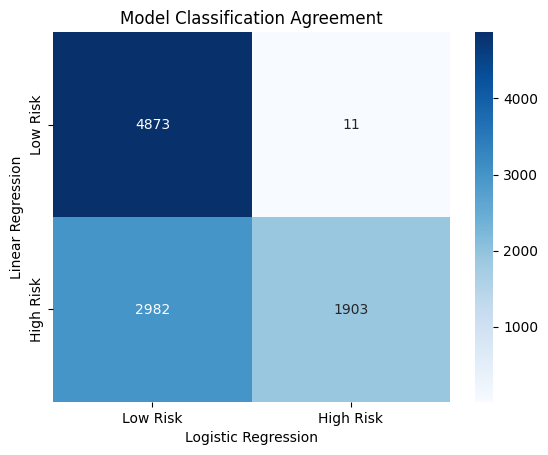

In [6]:

# STEP 4: MODEL COMPARISON

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    linear_class,
    logistic_class,
    labels=[0, 1]
)

print("Confusion Matrix:")
print(cm)

mismatches = np.sum(linear_class != logistic_class)
total = len(y_test)

print("\nMismatched cases:", mismatches)
print("Mismatch percentage:", round(mismatches / total * 100, 2), "%")

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Logistic Regression")
plt.ylabel("Linear Regression")
plt.title("Model Classification Agreement")
plt.show()


In [16]:

# PART 2.1: SIMPSON'S PARADOX HUNT - CORRECTED

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Use original, unscaled training data
analysis_data = X_train.copy()
analysis_data["income"] = y_train

# Select relevant predictors
# Using raw numerical variables avoids one-hot multicollinearity
formula_full = (
    'income ~ age + Q("education-num") + '
    'Q("hours-per-week") + Q("capital-gain") + '
    'Q("capital-loss") + C(sex)'
)

formula_subgroup = (
    'income ~ age + Q("education-num") + '
    'Q("hours-per-week") + Q("capital-gain") + '
    'Q("capital-loss")'
)

# Function to fit logistic regression
def fit_logistic_group(data, group_name, formula):

    model = smf.glm(
        formula=formula,
        data=data,
        family=sm.families.Binomial()
    ).fit()

    confidence = model.conf_int().loc["age"]

    return {
        "Group": group_name,
        "Age Coefficient": model.params["age"],
        "Standard Error": model.bse["age"],
        "P-value": model.pvalues["age"],
        "CI Lower": confidence.iloc[0],
        "CI Upper": confidence.iloc[1],
        "Sample Size": len(data)
    }

# Full training dataset
full_result = fit_logistic_group(
    analysis_data,
    "Full Dataset",
    formula_full
)

# Male subgroup
male_data = analysis_data[
    analysis_data["sex"] == "Male"
]

male_result = fit_logistic_group(
    male_data,
    "Male",
    formula_subgroup
)

# Female subgroup
female_data = analysis_data[
    analysis_data["sex"] == "Female"
]

female_result = fit_logistic_group(
    female_data,
    "Female",
    formula_subgroup
)

# Combine results
simpson_results = pd.DataFrame([
    full_result,
    male_result,
    female_result
])

print("CORRECTED SIMPSON'S PARADOX ANALYSIS")
display(simpson_results.round(6))

# Interpret coefficient direction
print("\nINTERPRETATION")

for _, row in simpson_results.iterrows():

    direction = (
        "Positive" if row["Age Coefficient"] > 0
        else "Negative"
    )

    print(
        row["Group"],
        ": Age coefficient =",
        round(row["Age Coefficient"], 6),
        "| Direction:",
        direction,
        "| P-value:",
        round(row["P-value"], 6)
    )

# Check whether signs reverse
signs = simpson_results["Age Coefficient"]

if (signs > 0).all() or (signs < 0).all():
    print("\nNo coefficient sign reversal detected.")
    print("Compare coefficient magnitudes and confidence intervals.")
else:
    print("\nCoefficient sign reversal detected.")



CORRECTED SIMPSON'S PARADOX ANALYSIS


,Group,Age Coefficient,Standard Error,P-value,CI Lower,CI Upper,Sample Size
0,Full Dataset,0.041115,0.001484,0.0,0.038207,0.044023,22792
1,Male,0.045472,0.001707,0.0,0.042127,0.048818,15255
2,Female,0.027097,0.003100,0.0,0.021021,0.033172,7537



INTERPRETATION
Full Dataset : Age coefficient = 0.041115 | Direction: Positive | P-value: 0.0
Male : Age coefficient = 0.045472 | Direction: Positive | P-value: 0.0
Female : Age coefficient = 0.027097 | Direction: Positive | P-value: 0.0

No coefficient sign reversal detected.
Compare coefficient magnitudes and confidence intervals.


In [17]:

# PART 2.2: OMITTED VARIABLE BIAS - CORRECTED

from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

feature_names = list(
    preprocessor.get_feature_names_out()
)

# FULL MODEL
full_model = LogisticRegression(
    max_iter=3000,
    C=1.0,
    solver="lbfgs"
)

full_model.fit(X_train_processed, y_train)

# Identify education-related columns
education_columns = [
    i for i, name in enumerate(feature_names)
    if (
        name == "num__education-num"
        or name.startswith("cat__education_")
    )
]

# Retain all other predictors
keep_columns = [
    i for i in range(len(feature_names))
    if i not in education_columns
]

# REDUCED MODEL
X_train_reduced = X_train_processed[:, keep_columns]

reduced_model = LogisticRegression(
    max_iter=3000,
    C=1.0,
    solver="lbfgs"
)

reduced_model.fit(X_train_reduced, y_train)

# Compare four coefficients
selected_features = [
    "num__age",
    "num__hours-per-week",
    "num__capital-gain",
    "num__capital-loss"
]

results = []

for feature in selected_features:

    original_index = feature_names.index(feature)

    full_coefficient = full_model.coef_[0][original_index]

    reduced_index = keep_columns.index(original_index)

    reduced_coefficient = reduced_model.coef_[0][reduced_index]

    percentage_change = (
        (reduced_coefficient - full_coefficient)
        / abs(full_coefficient)
    ) * 100 if abs(full_coefficient) > 1e-10 else np.nan

    results.append({
        "Predictor": feature,
        "Full Model Coefficient": full_coefficient,
        "Reduced Model Coefficient": reduced_coefficient,
        "Percentage Change": percentage_change
    })

bias_table = pd.DataFrame(results)

print("OMITTED VARIABLES:")
print("education-num and categorical education")

print("\nCOEFFICIENT COMPARISON:")
display(bias_table.round(6))

# Identify largest coefficient shift
largest_change = bias_table.loc[
    bias_table["Percentage Change"].abs().idxmax()
]

print("\nLARGEST COEFFICIENT CHANGE:")
print("Predictor:", largest_change["Predictor"])
print("Percentage change:",
      round(largest_change["Percentage Change"], 4), "%")



OMITTED VARIABLES:
education-num and categorical education

COEFFICIENT COMPARISON:


,Predictor,Full Model Coefficient,Reduced Model Coefficient,Percentage Change
0,num__age,0.290577,0.222372,-23.472230
1,num__hours-per-week,0.374286,0.419027,11.953736
2,num__capital-gain,2.220515,2.253579,1.489032
3,num__capital-loss,0.240665,0.252273,4.823338



LARGEST COEFFICIENT CHANGE:
Predictor: num__age
Percentage change: -23.4722 %


In [11]:

# PART 2.3: ADVERSARIAL SUBSET CONSTRUCTION

# Use logistic regression probabilities from Part 1
actual = y_test.values
probabilities = logistic_probabilities

# Identify confident but incorrect predictions
false_positives = (
    (probabilities >= 0.75) & (actual == 0)
)

false_negatives = (
    (probabilities <= 0.25) & (actual == 1)
)

wrong_indices = np.where(
    false_positives | false_negatives
)[0]

# Create a reproducible sample of up to 50 cases
rng = np.random.RandomState(37)

sample_indices = rng.choice(
    wrong_indices,
    size=min(50, len(wrong_indices)),
    replace=False
)

# Extract corresponding original records
adversarial_rows = X_test.iloc[sample_indices].copy()

adversarial_rows["Actual Income"] = actual[sample_indices]
adversarial_rows["Predicted Probability"] = probabilities[sample_indices]
adversarial_rows["Error Type"] = np.where(
    probabilities[sample_indices] >= 0.75,
    "False Positive",
    "False Negative"
)

print("Total high-confidence wrong predictions:", len(wrong_indices))
print("Percentage of test set:",
      round(len(wrong_indices) / len(y_test) * 100, 2), "%")

print("\nAdversarial sample:")
display(adversarial_rows.head(10))

print("\nGender distribution:")
print(adversarial_rows["sex"].value_counts(normalize=True) * 100)

print("\nAge statistics:")
print(adversarial_rows["age"].describe())

print("\nError types:")
print(adversarial_rows["Error Type"].value_counts())


Total high-confidence wrong predictions: 450
Percentage of test set: 4.61 %

Adversarial sample:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,Actual Income,Predicted Probability,Error Type
27727,41,Private,37997,12th,8,Divorced,Transport-moving,Not-in-family,White,Male,0,0,84,United-States,1,0.127283,False Negative
8801,58,Private,163113,HS-grad,9,Widowed,Sales,Not-in-family,White,Female,0,0,35,United-States,1,0.049856,False Negative
16525,44,Self-emp-inc,64632,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,0,0.903636,False Positive
13954,41,Self-emp-not-inc,151990,Assoc-voc,11,Married-civ-spouse,Prof-specialty,Wife,White,Female,0,0,15,United-States,1,0.245392,False Negative
17834,29,Self-emp-not-inc,341672,HS-grad,9,Married-spouse-absent,Transport-moving,Other-relative,Asian-Pac-Islander,Male,0,1564,50,India,1,0.020256,False Negative
14917,35,Private,113481,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,60,United-States,0,0.859604,False Positive
17466,36,Private,143774,Some-college,10,Married-civ-spouse,Adm-clerical,Wife,White,Female,0,0,12,United-States,1,0.198083,False Negative
1462,30,Private,177675,Some-college,10,Never-married,Craft-repair,Not-in-family,White,Male,0,0,40,United-States,1,0.043171,False Negative
154,52,NaN,252903,HS-grad,9,Divorced,NaN,Not-in-family,White,Male,0,0,45,United-States,1,0.098904,False Negative
14478,47,State-gov,80282,Doctorate,16,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,45,United-States,0,0.806787,False Positive



Gender distribution:
sex
Male      72.0
Female    28.0
Name: proportion, dtype: float64

Age statistics:
count    50.000000
mean     44.580000
std      10.020571
min      26.000000
25%      35.250000
50%      44.500000
75%      52.000000
max      66.000000
Name: age, dtype: float64

Error types:
Error Type
False Negative    40
False Positive    10
Name: count, dtype: int64


In [12]:

# ADDITIONAL: ADVERSARIAL DEMOGRAPHIC COMPARISON

print("ADVERSARIAL SUBSET ANALYSIS")

for col in ["sex", "race", "workclass", "education"]:

    print(f"\nComparison for {col}")

    adversarial_pct = (
        adversarial_rows[col]
        .value_counts(normalize=True) * 100
    )

    full_test_pct = (
        X_test[col]
        .value_counts(normalize=True) * 100
    )

    comparison = pd.DataFrame({
        "Adversarial Subset (%)": adversarial_pct,
        "Full Test Set (%)": full_test_pct
    }).fillna(0)

    comparison["Difference (%)"] = (
        comparison["Adversarial Subset (%)"]
        - comparison["Full Test Set (%)"]
    )

    display(comparison.round(2))

# Common characteristic
print("\nAGE COMPARISON")

print("Adversarial mean age:",
      adversarial_rows["age"].mean())

print("Full test mean age:",
      X_test["age"].mean())

print("\nHigh-confidence error types:")
display(adversarial_rows["Error Type"].value_counts())


ADVERSARIAL SUBSET ANALYSIS

Comparison for sex


,Adversarial Subset (%),Full Test Set (%),Difference (%)
sex,,,
Male,72.0,66.9,5.1
Female,28.0,33.1,-5.1



Comparison for race


,Adversarial Subset (%),Full Test Set (%),Difference (%)
race,,,
Amer-Indian-Eskimo,0.0,0.76,-0.76
Asian-Pac-Islander,4.0,3.56,0.44
Black,10.0,9.35,0.65
Other,0.0,0.83,-0.83
White,86.0,85.51,0.49



Comparison for workclass


,Adversarial Subset (%),Full Test Set (%),Difference (%)
workclass,,,
Federal-gov,0.00,3.20,-3.20
Local-gov,4.17,6.88,-2.72
Private,70.83,73.76,-2.93
Self-emp-inc,6.25,3.49,2.76
Self-emp-not-inc,14.58,8.39,6.19
State-gov,4.17,4.23,-0.06
Without-pay,0.00,0.04,-0.04



Comparison for education


,Adversarial Subset (%),Full Test Set (%),Difference (%)
education,,,
10th,2.0,2.95,-0.95
11th,8.0,3.46,4.54
12th,6.0,1.27,4.73
1st-4th,0.0,0.49,-0.49
5th-6th,2.0,1.05,0.95
7th-8th,0.0,2.09,-2.09
9th,0.0,1.76,-1.76
Assoc-acdm,0.0,3.07,-3.07
Assoc-voc,2.0,4.38,-2.38



AGE COMPARISON
Adversarial mean age: 44.58
Full test mean age: 38.6651653188658

High-confidence error types:


,count
Error Type,
False Negative,40
False Positive,10


FAIRNESS METRICS TABLE


,Threshold,DP,EO,PP
0,0.05,2.1832,1.0547,1.3538
1,0.15,3.3100,1.1346,0.9606
2,0.25,3.3560,1.1608,0.9693
3,0.35,3.2174,1.1342,0.9879
4,0.45,3.4148,1.2062,0.9899
5,0.55,3.6470,1.2980,0.9974
6,0.65,3.6214,1.3022,1.0077
7,0.75,3.3307,1.2361,1.0401
8,0.85,3.3934,1.1960,0.9877
9,0.95,3.5796,1.2970,1.0154


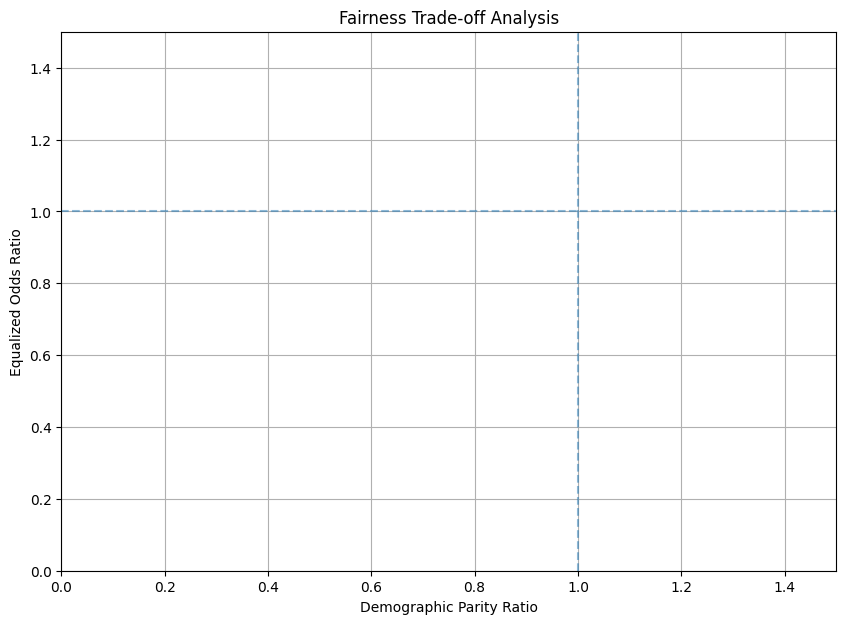

In [13]:

# PART 2.4: FAIRNESS TRADE-OFF ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Select sensitive variable
group_values = X_test["sex"].values

# Group A and Group B
group_A = "Male"
group_B = "Female"

# Decision thresholds
thresholds = np.round(np.arange(0.05, 1.00, 0.10), 2)

fairness_results = []

def safe_ratio(a, b):
    if b == 0:
        return np.nan
    return a / b

for threshold in thresholds:

    predictions = (logistic_probabilities >= threshold).astype(int)

    metrics = {}

    for group in [group_A, group_B]:

        mask = (group_values == group)

        y_true = y_test.values[mask]
        y_pred = predictions[mask]

        # Demographic Parity
        dp = np.mean(y_pred == 1)

        # True Positive Rate
        actual_positive = (y_true == 1)
        tpr = (
            np.sum((y_pred == 1) & actual_positive)
            / np.sum(actual_positive)
            if np.sum(actual_positive) > 0 else np.nan
        )

        # False Positive Rate
        actual_negative = (y_true == 0)
        fpr = (
            np.sum((y_pred == 1) & actual_negative)
            / np.sum(actual_negative)
            if np.sum(actual_negative) > 0 else np.nan
        )

        # Predictive Parity
        predicted_positive = (y_pred == 1)
        pp = (
            np.mean(y_true[predicted_positive] == 1)
            if np.sum(predicted_positive) > 0 else np.nan
        )

        metrics[group] = {
            "DP": dp,
            "TPR": tpr,
            "FPR": fpr,
            "PP": pp
        }

    A = metrics[group_A]
    B = metrics[group_B]

    # Calculate fairness ratios
    DP_ratio = safe_ratio(A["DP"], B["DP"])

    EO_TPR = safe_ratio(A["TPR"], B["TPR"])
    EO_FPR = safe_ratio(A["FPR"], B["FPR"])

    EO_ratio = np.nanmin([EO_TPR, EO_FPR]) if not (
        np.isnan(EO_TPR) and np.isnan(EO_FPR)
    ) else np.nan

    PP_ratio = safe_ratio(A["PP"], B["PP"])

    fairness_results.append({
        "Threshold": threshold,
        "DP": DP_ratio,
        "EO": EO_ratio,
        "PP": PP_ratio
    })

# Create fairness table
fairness_df = pd.DataFrame(fairness_results)

print("FAIRNESS METRICS TABLE")
display(fairness_df.round(4))

# Trade-off chart
plt.figure(figsize=(10, 7))

plt.plot(
    fairness_df["DP"],
    fairness_df["EO"],
    marker="o"
)

for _, row in fairness_df.iterrows():
    plt.annotate(
        f"t={row['Threshold']:.2f}",
        (row["DP"], row["EO"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.axhline(1, linestyle="--", alpha=0.5)
plt.axvline(1, linestyle="--", alpha=0.5)

plt.xlabel("Demographic Parity Ratio")
plt.ylabel("Equalized Odds Ratio")
plt.title("Fairness Trade-off Analysis")
plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.grid(True)
plt.show()


In [14]:

# ADDITIONAL: FAIRNESS TRADE-OFF QUANTIFICATION

print("FAIRNESS TRADE-OFF ANALYSIS")

fairness_df["DP Distance"] = (
    fairness_df["DP"] - 1
).abs()

fairness_df["EO Distance"] = (
    fairness_df["EO"] - 1
).abs()

# Find thresholds with the best DP and EO parity
best_dp_index = fairness_df["DP Distance"].idxmin()
best_eo_index = fairness_df["EO Distance"].idxmin()

best_dp = fairness_df.loc[best_dp_index]
best_eo = fairness_df.loc[best_eo_index]

print("\nBest DP threshold:")
display(best_dp)

print("\nBest EO threshold:")
display(best_eo)

print("\nPredictive parity across thresholds:")
display(fairness_df[["Threshold", "PP"]])

# Compare the two selected operating points
dp_change = best_dp["DP"]
eo_change = best_eo["EO"]

print("\nInterpretation:")
print("Threshold with closest DP parity:",
      best_dp["Threshold"])
print("Threshold with closest EO parity:",
      best_eo["Threshold"])

print("DP ratio at selected DP threshold:",
      round(best_dp["DP"], 4))

print("EO ratio at selected EO threshold:",
      round(best_eo["EO"], 4))


FAIRNESS TRADE-OFF ANALYSIS

Best DP threshold:


,0
Threshold,0.050000
DP,2.183186
EO,1.054699
PP,1.353849
DP Distance,1.183186
EO Distance,0.054699



Best EO threshold:


,0
Threshold,0.050000
DP,2.183186
EO,1.054699
PP,1.353849
DP Distance,1.183186
EO Distance,0.054699



Predictive parity across thresholds:


,Threshold,PP
0,0.05,1.353849
1,0.15,0.960613
2,0.25,0.969336
3,0.35,0.987882
4,0.45,0.989914
5,0.55,0.997448
6,0.65,1.007667
7,0.75,1.040052
8,0.85,0.987689
9,0.95,1.015414



Interpretation:
Threshold with closest DP parity: 0.05
Threshold with closest EO parity: 0.05
DP ratio at selected DP threshold: 2.1832
EO ratio at selected EO threshold: 1.0547


In [15]:

# ADDITIONAL: THRESHOLD-WISE CLASSIFICATION PERFORMANCE

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

performance_results = []

for threshold in thresholds:

    pred = (
        logistic_probabilities >= threshold
    ).astype(int)

    performance_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(
            y_test, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, pred, zero_division=0
        )
    })

performance_df = pd.DataFrame(performance_results)

display(performance_df.round(4))


,Threshold,Accuracy,Precision,Recall,F1 Score
0,0.05,0.6273,0.3903,0.9753,0.5575
1,0.15,0.7638,0.5052,0.9281,0.6543
2,0.25,0.8165,0.5809,0.8533,0.6912
3,0.35,0.8437,0.6515,0.7543,0.6991
4,0.45,0.8527,0.7132,0.6492,0.6797
5,0.55,0.8486,0.7569,0.5468,0.6349
6,0.65,0.8415,0.8201,0.4379,0.5710
7,0.75,0.8287,0.8819,0.3333,0.4838
8,0.85,0.8080,0.9327,0.2181,0.3535
9,0.95,0.7835,0.9798,0.1029,0.1862


In [19]:

# STEP 8: FINAL ASSIGNMENT RESULTS COLLECTION

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from IPython.display import display

print("=" * 60)
print("CSET485 - AI AND SOCIETY: FINAL RESULTS")
print("=" * 60)

# 1. MODEL COMPARISON
print("\n1. MODEL COMPARISON")

print("Linear Regression Median:", median_threshold)
print("Linear Regression Accuracy:",
      accuracy_score(y_test, linear_class))

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, logistic_class))

print("Mismatch Count:", mismatches)
print("Mismatch Percentage:",
      round(mismatches / len(y_test) * 100, 2), "%")

# 2. SIMPSON'S PARADOX
print("\n2. SIMPSON'S PARADOX RESULTS")
display(simpson_results.round(4))

# 3. OMITTED VARIABLE BIAS
print("\n3. OMITTED VARIABLE BIAS RESULTS")
display(bias_table.round(4))

# 4. ADVERSARIAL SUBSET
print("\n4. ADVERSARIAL SUBSET RESULTS")

print("Total high-confidence errors:", len(wrong_indices))
print("Percentage of test set:",
      round(len(wrong_indices) / len(y_test) * 100, 2), "%")

print("\nAdversarial demographics:")
display(adversarial_rows[["age", "sex", "race"]].describe(include="all"))

print("\nAdversarial gender distribution:")
display(adversarial_rows["sex"].value_counts())

print("\nFull test gender distribution:")
display(X_test["sex"].value_counts())

print("\nAdversarial race distribution:")
display(adversarial_rows["race"].value_counts())

# 5. FAIRNESS METRICS
print("\n5. FAIRNESS METRICS")
display(fairness_df.round(4))

# 6. EXPORT ALL TABLES
simpson_results.to_csv("simpson_results.csv", index=False)
bias_table.to_csv("omitted_variable_bias.csv", index=False)
adversarial_rows.to_csv("adversarial_subset.csv", index=False)
fairness_df.to_csv("fairness_results.csv", index=False)

print("\nAll result tables exported successfully!")
print("Your assignment analysis is complete.")
simpson_results.to_csv("corrected_simpson_results.csv", index=False)
bias_table.to_csv("corrected_bias_results.csv", index=False)


CSET485 - AI AND SOCIETY: FINAL RESULTS

1. MODEL COMPARISON
Linear Regression Median: 0.22084226947688904
Linear Regression Accuracy: 0.7089773774183642
Logistic Regression Accuracy: 0.8527996724332071
Mismatch Count: 2993
Mismatch Percentage: 30.64 %

2. SIMPSON'S PARADOX RESULTS


,Group,Age Coefficient,Standard Error,P-value,CI Lower,CI Upper,Sample Size
0,Full Dataset,0.0411,0.0015,0.0,0.0382,0.0440,22792
1,Male,0.0455,0.0017,0.0,0.0421,0.0488,15255
2,Female,0.0271,0.0031,0.0,0.0210,0.0332,7537



3. OMITTED VARIABLE BIAS RESULTS


,Predictor,Full Model Coefficient,Reduced Model Coefficient,Percentage Change
0,num__age,0.2906,0.2224,-23.4722
1,num__hours-per-week,0.3743,0.4190,11.9537
2,num__capital-gain,2.2205,2.2536,1.4890
3,num__capital-loss,0.2407,0.2523,4.8233



4. ADVERSARIAL SUBSET RESULTS
Total high-confidence errors: 450
Percentage of test set: 4.61 %

Adversarial demographics:


,age,sex,race
count,50.000000,50,50
unique,NaN,2,3
top,NaN,Male,White
freq,NaN,36,43
mean,44.580000,NaN,NaN
std,10.020571,NaN,NaN
min,26.000000,NaN,NaN
25%,35.250000,NaN,NaN
50%,44.500000,NaN,NaN
75%,52.000000,NaN,NaN


... (5 outputs left out)

,count
race,
White,43
Black,5
Asian-Pac-Islander,2



5. FAIRNESS METRICS


,Threshold,DP,EO,PP,DP Distance,EO Distance
0,0.05,2.1832,1.0547,1.3538,1.1832,0.0547
1,0.15,3.3100,1.1346,0.9606,2.3100,0.1346
2,0.25,3.3560,1.1608,0.9693,2.3560,0.1608
3,0.35,3.2174,1.1342,0.9879,2.2174,0.1342
4,0.45,3.4148,1.2062,0.9899,2.4148,0.2062
5,0.55,3.6470,1.2980,0.9974,2.6470,0.2980
6,0.65,3.6214,1.3022,1.0077,2.6214,0.3022
7,0.75,3.3307,1.2361,1.0401,2.3307,0.2361
8,0.85,3.3934,1.1960,0.9877,2.3934,0.1960
9,0.95,3.5796,1.2970,1.0154,2.5796,0.2970



All result tables exported successfully!
Your assignment analysis is complete.
